# Ce Notebook contient les principales étapes de l'analyse ainsi que les résultats

*Projet Python pour la Data Science — Elisa Desloges, Maxime Girard, Amélie Thiebault — 2026*

## Introduction

3,5 % : c’est la part de la population qu’il faudrait pour faire tomber n’importe quel gouvernement.

Cette règle a été théorisée par la chercheuse américaine Erica Chenoweth en 2013 dans Why Civil Resistance Works. En étudiant 323 mouvements de contestation entre 1900 et 2006, les chercheuses ont observé qu'aucun gouvernement n'a résisté face à un mouvement de résistance civile non violente ayant réussi à mobiliser au moins 3,5 % de la population de son pays au plus fort de la crise.

Dans le contexte actuel de mobilisations en Europe, nous avons décidé de mettre à l’épreuve cette règle et d’analyser ce qui fait qu’une mobilisation réussie ou non.

Qu'est-ce qu'un soulèvement réussi ? La participation suffit-elle à expliquer le succès d'une mobilisation ?

## Sommaire

- [Importation des modules](#installation)
- [Importation des bases de données](#donnees)
- [Nettoyage des données](#nettoyage)
- [Lien entre taux de participation et réussite du mouvement](#participation)
- [Etude de la violence](#violence)
    - [Classification des campagnes](#class)
    - [Issue de chaque campagne](#issue)
    - [Méthode et succès](#methode)

- [Conclusions](#conclu)

## Importation des modules

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import nbformat as nb

## Importation des bases de données

In [3]:
# Importation de la base 1 (NAVCO 2.1)
navco = pd.read_excel("Data/base2-1.xls")

# Importation de la base de population
pop = pd.read_csv("Data/population.csv", sep=",")

data_clean = False

## Nettoyage des données

In [4]:
if data_clean == False:
    with open("Cleanup.ipynb", "r", encoding="utf-8") as f:
        cleanup_nb = nb.read(f, as_version=4)

    # Use the current notebook's namespace
    namespace = globals()

    # Execute all code cells sequentially
    for cell in cleanup_nb.cells:
        if cell.cell_type == "code":
            exec(cell.source, namespace)  # noqa: S102
    
    data_clean = True

2717 2717
_merge
both          2699
left_only       18
right_only       0
Name: count, dtype: int64
     location  year
South Vietnam  1958
South Vietnam  1959
South Vietnam  1960
South Vietnam  1961
South Vietnam  1962
South Vietnam  1963
South Vietnam  1964
South Vietnam  1965
South Vietnam  1966
        Tibet  1956
        Tibet  1957
        Tibet  1958
        Tibet  1959
        Tibet  1987
        Tibet  1988
        Tibet  1989
      location  year  total_part_clean  Population  pourcent_part
0   Madagascar  1991          400000.0  12421413.0       3.220246
1   Madagascar  1992               NaN  12800870.0            NaN
2   Madagascar  1993               NaN  13197353.0            NaN
3     Djibouti  1991            3000.0    631096.0       0.475363
4     Djibouti  1992            4500.0    626016.0       0.718831
5     Djibouti  1993            4500.0    614247.0       0.732604
6     Djibouti  1994            4500.0    626717.0       0.718027
7  Afghanistan  1979           1

## Lien entre taux de participation et réussite du mouvement

In [5]:
# Calcul de la corrélation de Spearman

spearman_corr, p_value = stats.spearmanr( df_pc_pop["pourcent_part"], df_pc_pop["progress2"]) # corrélation de Spearman

print(f"Corr de Spearman : {spearman_corr:.4f}") #ici on regarde année par année les mouvements donc certains sont représentés plusieurs fois
print(f"P-value : {p_value:.4e}")

Corr de Spearman : 0.2538
P-value : 1.2482e-34


In [6]:
# Prise en compte uniquement du pic de participation

mouv_peak = (
    navco_pop.sort_values(["id", "year"])
    .groupby("id")
    .agg(
        location=("location", "first"),
        pic_pourcent=("pourcent_part", "max"),      # pic de participation
        success=("success", "last"),                # dernière ligne = résultat final
    )
    .reset_index()
)

print(mouv_peak.shape)                      

print("Mouvements sans pic calculable :", mouv_peak["pic_pourcent"].isna().sum())

(384, 4)
Mouvements sans pic calculable : 20


In [7]:
mouv_peak = mouv_peak.dropna(subset=["pic_pourcent"]).copy()    
mouv_peak["tranche"] = pd.qcut(mouv_peak["pic_pourcent"], q=10, duplicates="drop")
print(mouv_peak.groupby("tranche", observed=True)["success"].agg(n="count", taux="mean"))

mouv_peak["au_dessus"] = mouv_peak["pic_pourcent"] >= 3.5
print(mouv_peak.groupby("au_dessus")["success"].agg(n="count", taux="mean"))
print(mouv_peak[(mouv_peak["au_dessus"]) & (mouv_peak["success"] == 0)])   # les exceptions

                       n      taux
tranche                           
(-0.0009694, 0.0139]  37  0.027027
(0.0139, 0.0428]      36  0.194444
(0.0428, 0.0894]      36  0.194444
(0.0894, 0.158]       37  0.378378
(0.158, 0.259]        36  0.361111
(0.259, 0.524]        36  0.444444
(0.524, 0.896]        37  0.540541
(0.896, 1.85]         36  0.472222
(1.85, 4.664]         36  0.555556
(4.664, 33.751]       37  0.648649
             n      taux
au_dessus               
False      321  0.348910
True        43  0.627907
      id                      location  pic_pourcent  success  \
18    21                      Pakistan      4.276359        0   
21    24                        Panama     32.580662        0   
58    64                Czechoslovakia     24.441341        0   
67    74                  East Germany     10.875476        0   
76    83                    Madagascar      5.356130        0   
151  164                     Palestine     33.750774        0   
171  184           Yemen 

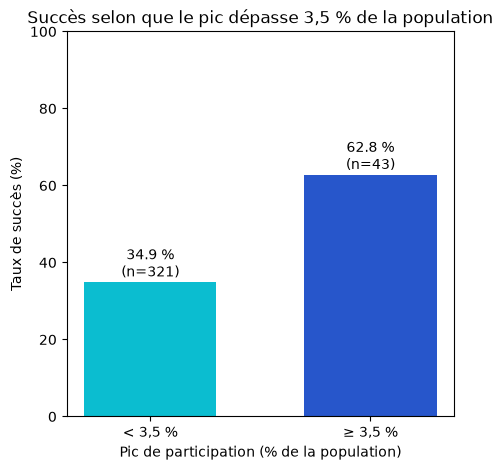

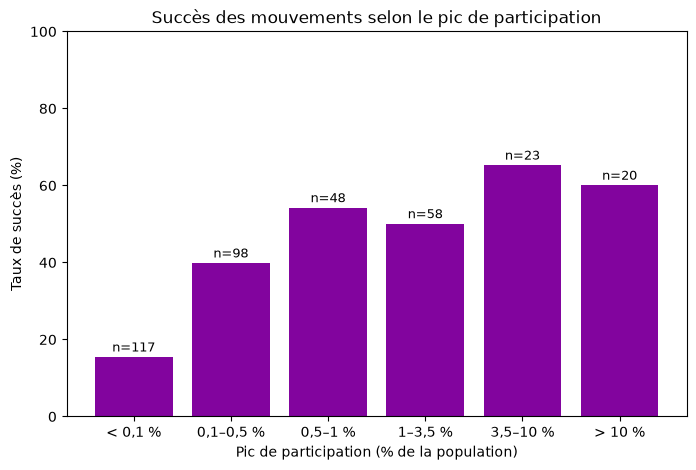

In [15]:
tab1 = mouv_peak.groupby("au_dessus")["success"].agg(n="count", taux="mean")
labels = ["< 3,5 %", "≥ 3,5 %"]          # False puis True, dans cet ordre

fig, ax = plt.subplots(figsize=(5, 5))
ax.bar(labels, tab1["taux"] * 100, color=["#0BBDD0", "#2756CB"], width=0.6)

for i, (t, n) in enumerate(zip(tab1["taux"], tab1["n"])):  #pour afficher l'effectif de chaque barre
    ax.text(i, t * 100 + 1.5, f"{t*100:.1f} %\n(n={n})", ha="center", fontsize=10)

ax.set_ylabel("Taux de succès (%)")
ax.set_xlabel("Pic de participation (% de la population)")
ax.set_title("Succès selon que le pic dépasse 3,5 % de la population")
ax.set_ylim(0, 100)
plt.savefig("Graphiques/graph_seuil_3_5.png", dpi=200, bbox_inches="tight")
plt.show()

bins   = [0, 0.1, 0.5, 1, 3.5, 10, 35]
labels = ["< 0,1 %", "0,1–0,5 %", "0,5–1 %", "1–3,5 %", "3,5–10 %", "> 10 %"]

mouv_peak["classe"] = pd.cut(mouv_peak["pic_pourcent"], bins=bins,
                             labels=labels, include_lowest=True)
tab2 = mouv_peak.groupby("classe", observed=True)["success"].agg(n="count", taux="mean")

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(tab2.index, tab2["taux"] * 100, color="#82049E")
for i, (t, n) in enumerate(zip(tab2["taux"], tab2["n"])):
    ax.text(i, t * 100 + 1.5, f"n={n}", ha="center", fontsize=9)

ax.set_ylabel("Taux de succès (%)")
ax.set_xlabel("Pic de participation (% de la population)")
ax.set_title("Succès des mouvements selon le pic de participation")
ax.set_ylim(0, 100)
plt.savefig("Graphiques/graph_participation_succes.png", dpi=200, bbox_inches="tight")
plt.show()

## Etude de la violence

### Classification des campagnes

In [9]:
camp = (navco2.groupby("id")
        .agg(camp_name=("camp_name", "first"),
             location=("location", "first"),
             debut=("start_year", "first"),
             fin=("end_year", "first"),
             duree=("camp_duration", "first"),
             nb_annees=("year", "count"),
             violente_moy=("violente", "mean"),
             intensite_max=("camp_confl_intensity", "max"),
             intensite_moy=("camp_confl_intensity", "mean"),
             repression_max=("repression", "max"))
        .reset_index())
camp["violente"] = (camp["violente_moy"] > 0.5).astype(int)
camp["mixte"] = camp["violente_moy"].between(0.01, 0.99)

### Issue de chaque campagne

In [10]:
derniere = navco2.groupby("id").tail(1).set_index("id")
camp["annee_finale"] = camp["id"].map(derniere["year"])
camp["progress_final"] = camp["id"].map(derniere["progress2"])
camp["status"] = camp["id"].map(derniere["status"])
camp["success"] = camp["id"].map(navco2.groupby("id")["success"].max())

camp["issue"] = np.select(
    [camp["success"] == 1, camp["status"] == 0],
    ["succes", "echec"],
    default="en_cours")

### Méthode et succès

Nous avons choisit d'exclure les campagnes en cours en 2013 car l'issue est inconnue.

Campagnes au total : 384
Campagnes en cours (exclues) : 53
Campagnes retenues : 331
dont mixtes : 21

            taux  succes    n
violente                    
0         0.592      87  147
1         0.326      60  184


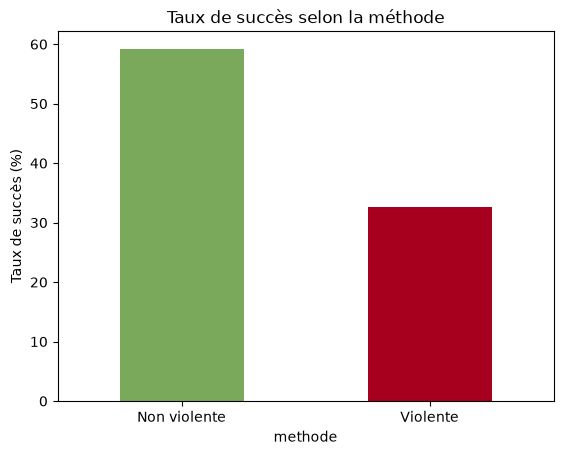

In [11]:
net = camp[camp["issue"] != "en_cours"].copy()

print("Campagnes au total :", len(camp))
print("Campagnes en cours (exclues) :", (camp["issue"] == "en_cours").sum())
print("Campagnes retenues :", len(net))
print("dont mixtes :", net["mixte"].sum())

tab = net.groupby("violente")["success"].agg(taux="mean", succes="sum", n="count").round(3)
print("\n", tab)

df = camp[camp["issue"] != "en_cours"].copy() # enlever les lignes avec valeur "en_cours" car leur résultat définitif n'est pas encore connu
df["methode"] = df["violente"].map({0: "Non violente", 1: "Violente"}) # nouvelle colonne avec la méthode (violente/non violente)

# Graph : succès selon la méthode
(df.groupby("methode")["success"].mean() * 100).plot(kind="bar", color=["#7AA95C", "#A7001E"])
plt.ylabel("Taux de succès (%)")
plt.title("Taux de succès selon la méthode")
plt.xticks(rotation=0)
plt.savefig("Graphiques/graph_succes_methode.png", dpi=200, bbox_inches="tight")
plt.show()

Sur les 331 campagnes dont l'issue est connue, 59 % des campagnes non violentes ont atteint leur objectif maximaliste (87 sur 147), contre 33 % des campagnes violentes (60 sur 184). Nous constatons un écart d'environ 27 points de pourcentage : les campagnes non violentes semble réussir presque deux fois plus souvent que les campagnes violentes.

In [12]:
ct = pd.crosstab(net["violente"], net["success"])
print("\n", ct)
odds, p = stats.fisher_exact(ct)
print(f"\nOdds ratio = {odds:.2f}, p = {p:.2e}")


 success     0   1
violente         
0          60  87
1         124  60

Odds ratio = 0.33, p = 1.56e-06


Le test exact de Fisher donne un odds ratio de 0,33. Les mobilisations violentes ont des chances de succès environ trois fois plus faibles en termes de cotes. 
La p-value très faible signifie qu'un écart de cette taille serait très improbable si la méthode n'avait aucun lien avec le succès.

Ainsi, la méthode employée lors des mobilisations est fortement associée à la réussite. Ce résultat va dans le sens des travaux de Chenoweth et Stephan, avec des taux du même ordre que ceux qu'ils rapportent.

### Succès selon l'intensité du conflit

In [13]:
print(pd.crosstab(navco2["violent_flank"], navco2["flank_intensity"].fillna(-1)))

# violence de la branche radicale
camp["flank_max"] = camp["id"].map(navco2.groupby("id")["flank_intensity"].max())
camp_finie = camp[camp["issue"] != "en_cours"].copy()

nv = camp_finie[camp_finie["violente"] == 0] # campagnes non violentes
print(nv["flank_max"].value_counts(dropna=False).sort_index())
print(nv.groupby("flank_max")["success"].agg(taux="mean", n="count").round(3))

flank_intensity  -1.0   0.0   1.0   2.0   3.0
violent_flank                                
0.0              2207     0     0     0     0
1.0                 0   208     0     0     0
2.0                 6     0    44    82   165
flank_max
0.0    33
1.0    17
2.0    43
3.0    52
NaN     2
Name: count, dtype: int64
            taux   n
flank_max           
0.0        0.636  33
1.0        0.412  17
2.0        0.651  43
3.0        0.596  52


flank_max
0.0     41
1.0     21
2.0     46
3.0     73
NaN    203
Name: count, dtype: int64


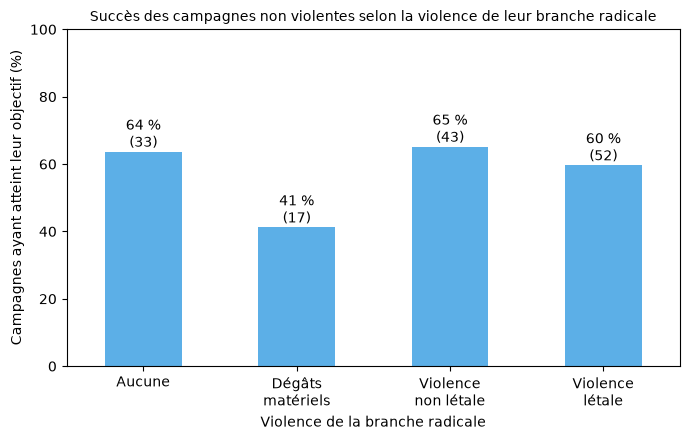

In [14]:
camp_finie = camp[camp["issue"] != "en_cours"].copy()
nv = camp_finie[camp_finie["violente"] == 0].copy()

camp["flank_max"] = camp["id"].map(navco2.groupby("id")["flank_intensity"].max())
print(camp["flank_max"].value_counts(dropna=False).sort_index())

label = {0: "Aucune", 1: "Dégâts\nmatériels", 2: "Violence\nnon létale", 3: "Violence\nlétale"}
nv["branche"] = nv["flank_max"].map(label)

ordre = list(label.values())
taux = nv.groupby("branche")["success"].mean().reindex(ordre) * 100
effectifs = nv.groupby("branche")["success"].count().reindex(ordre)

ax = taux.plot(kind="bar", color="#5CAFE7", figsize=(7, 4.5))
for i, niveau in enumerate(ordre):
    ax.text(i, taux[niveau] + 1.5, f"{taux[niveau]:.0f} %\n({effectifs[niveau]})", ha="center")
ax.set_xlabel("Violence de la branche radicale")
ax.set_ylabel("Campagnes ayant atteint leur objectif (%)")
ax.set_ylim(0, 100)
ax.set_title("Succès des campagnes non violentes selon la violence de leur branche radicale")
ax.title.set_fontsize(10)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("Graphiques/graph_branche_violente.png", dpi=200, bbox_inches="tight")
plt.show()